# Climate Data Visualization

## Visualizing Climate Data with Python

Effective visualization is essential for understanding climate data. This notebook covers various plotting techniques using matplotlib and cartopy for climate data exploration and communication.

### Learning Objectives:
- Create time series plots for climate variables
- Generate spatial maps with different cartopy projections
- Design multi-panel figure layouts
- Produce anomaly maps, seasonal cycle plots, and histograms
- Use appropriate color schemes for climate data

In [1]:
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import os
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Use real data: NCEP/DOE temperature regridded onto the CHIRPS Ethiopia grid
data_dir = '../data'
os.makedirs(data_dir, exist_ok=True)

tas_file = os.path.join('..', 'datasets', 'tas_sample.nc')
pr_file = os.path.join('..', 'datasets', 'pr_sample.nc')

ds_pr_real = xr.open_dataset(pr_file)
# Coarsen the real CHIRPS grid so plotting stays fast
ds_pr_real = ds_pr_real.isel(latitude=slice(0, None, 5), longitude=slice(0, None, 5))

ds_tas_real = xr.open_dataset(tas_file)
# Interpolate the real reanalysis temperature onto the real CHIRPS grid
tas_on_pr = ds_tas_real.tas.interp(lat=ds_pr_real.latitude, lon=ds_pr_real.longitude)

ds = xr.Dataset(
    {
        'temperature': (['time', 'latitude', 'longitude'],
                        (tas_on_pr - 273.15).values,
                        {'units': 'degC', 'long_name': 'Surface temperature'}),
        'precipitation': (['time', 'latitude', 'longitude'],
                          ds_pr_real.pr.values,
                          {'units': 'mm/month', 'long_name': 'Precipitation'}),
    },
    coords={'time': ds_pr_real.time.values,
            'latitude': ds_pr_real.latitude.values,
            'longitude': ds_pr_real.longitude.values}
)
ds = ds.rename({'latitude': 'lat', 'longitude': 'lon'})
ds.attrs = {'title': 'Real reanalysis temperature + CHIRPS precipitation',
            'source': 'NCEP/DOE Reanalysis-2 + CHIRPS'}

lat = ds.lat.values
lon = ds.lon.values

vis_file = os.path.join(data_dir, 'real_visualization_data.nc')
ds.to_netcdf(vis_file)
print(f'Using real datasets: {tas_file}, {pr_file}')
print(f'Dimensions: {len(ds.lon)} lon x {len(ds.lat)} lat x {len(ds.time)} time')
print(ds)

Using real datasets: ..\datasets\tas_sample.nc, ..\datasets\pr_sample.nc
Dimensions: 60 lon x 48 lat x 372 time
<xarray.Dataset> Size: 13MB
Dimensions:        (time: 372, lat: 48, lon: 60)
Coordinates:
  * time           (time) datetime64[ns] 3kB 1980-01-01 ... 2010-12-01
  * lat            (lat) float32 192B 3.025 3.275 3.525 ... 14.27 14.52 14.77
  * lon            (lon) float32 240B 33.02 33.27 33.52 ... 47.27 47.52 47.77
Data variables:
    temperature    (time, lat, lon) float64 9MB 22.25 22.3 22.34 ... 20.51 20.75
    precipitation  (time, lat, lon) float32 4MB 5.609 4.555 ... 9.018 8.735
Attributes:
    title:    Real reanalysis temperature + CHIRPS precipitation
    source:   NCEP/DOE Reanalysis-2 + CHIRPS


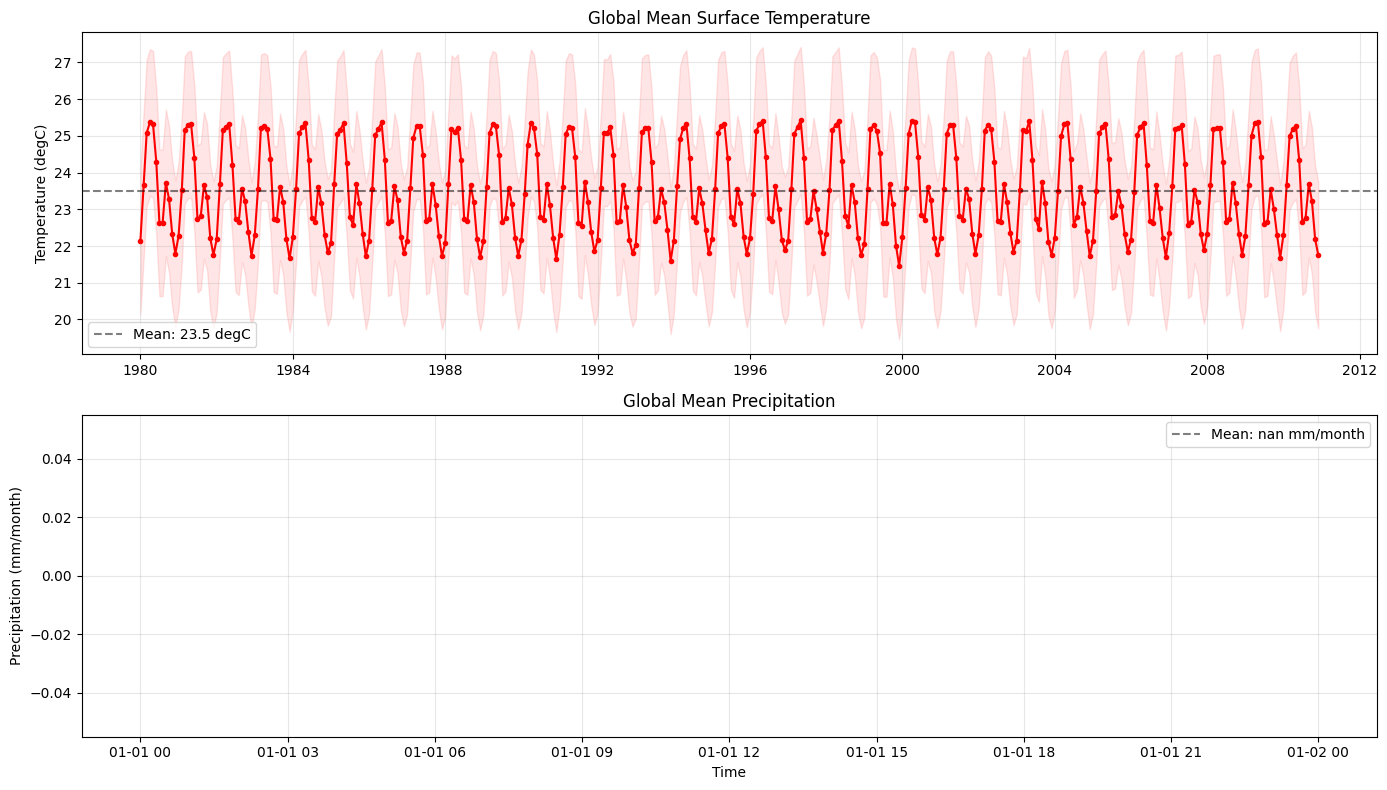

In [3]:
# Time series plotting (matplotlib)
# Compute global mean for each variable

# Manual area-weighted mean
lat_rad = np.deg2rad(ds.lat.values)
weights = np.broadcast_to(np.cos(lat_rad)[:, np.newaxis], (len(lat), len(lon)))

global_temp = ds.temperature.values
global_precip = ds.precipitation.values

ts_temp = np.average(global_temp, weights=weights / weights.sum(), axis=(-2, -1))
ts_precip = np.average(global_precip, weights=weights / weights.sum(), axis=(-2, -1))

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(ds.time, ts_temp, color='red', linewidth=1.5, marker='o', markersize=3)
axes[0].fill_between(ds.time.values, ts_temp - 2, ts_temp + 2, alpha=0.1, color='red')
axes[0].axhline(y=ts_temp.mean(), color='k', linestyle='--', alpha=0.5, label=f'Mean: {ts_temp.mean():.1f} degC')
axes[0].set_ylabel('Temperature (degC)')
axes[0].set_title('Global Mean Surface Temperature')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ds.time, ts_precip, color='blue', linewidth=1.5, marker='s', markersize=3)
axes[1].fill_between(ds.time.values, ts_precip - 1, ts_precip + 1, alpha=0.1, color='blue')
axes[1].axhline(y=ts_precip.mean(), color='k', linestyle='--', alpha=0.5, label=f'Mean: {ts_precip.mean():.1f} mm/month')
axes[1].set_ylabel('Precipitation (mm/month)')
axes[1].set_title('Global Mean Precipitation')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.xlabel('Time')
plt.tight_layout()
plt.show()

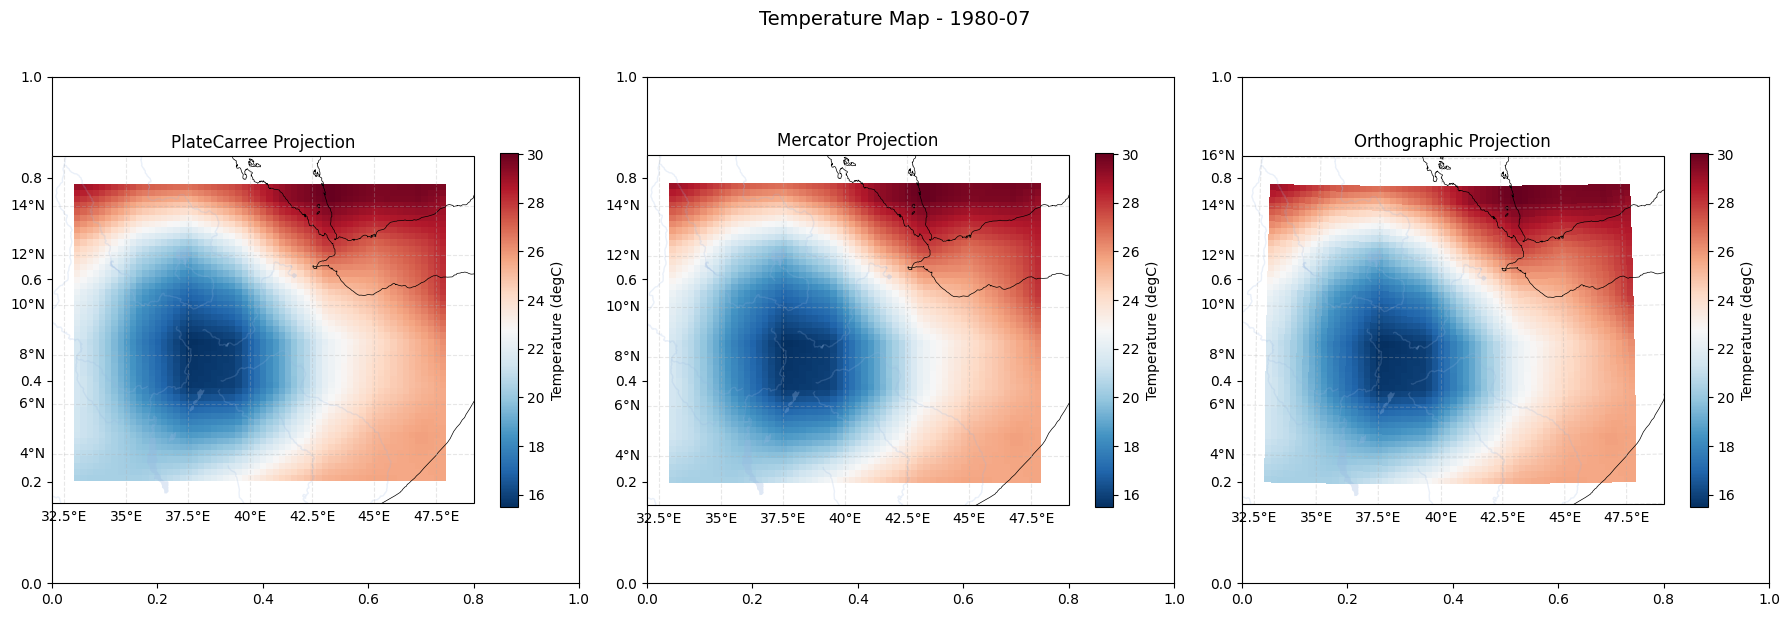

In [4]:
# Spatial map plotting (cartopy) with multiple projections

projections = [
    ('PlateCarree', ccrs.PlateCarree()),
    ('Mercator', ccrs.Mercator()),
    ('Orthographic', ccrs.Orthographic(40, 10)),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6),
                         subplot_kw={})

t_idx = 6  # July (index into the monthly series)

for ax, (proj_name, proj) in zip(axes, projections):
    ax = plt.subplot(1, 3, list(projections).index((proj_name, proj)) + 1,
                     projection=proj)

    data_2d = ds.temperature[t_idx]
    lon_vals = ds.lon.values
    lat_vals = ds.lat.values

    # Regional real-data domain: no cyclic point needed
    data_cyclic, lon_cyclic = data_2d.values, lon_vals

    im = ax.pcolormesh(lon_cyclic, lat_vals, data_cyclic,
                       cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.LAKES, alpha=0.3)
    ax.add_feature(cfeature.RIVERS, alpha=0.2)

    ax.set_extent([32, 49, 2, 16], crs=ccrs.PlateCarree())

    ax.set_title(f'{proj_name} Projection')
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
    gl.top_labels = False
    gl.right_labels = False

    cbar = plt.colorbar(im, ax=ax, orientation='vertical', shrink=0.7, pad=0.05)
    cbar.set_label('Temperature (degC)')

plt.suptitle(f'Temperature Map - {str(ds.time[t_idx].values)[:7]}', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

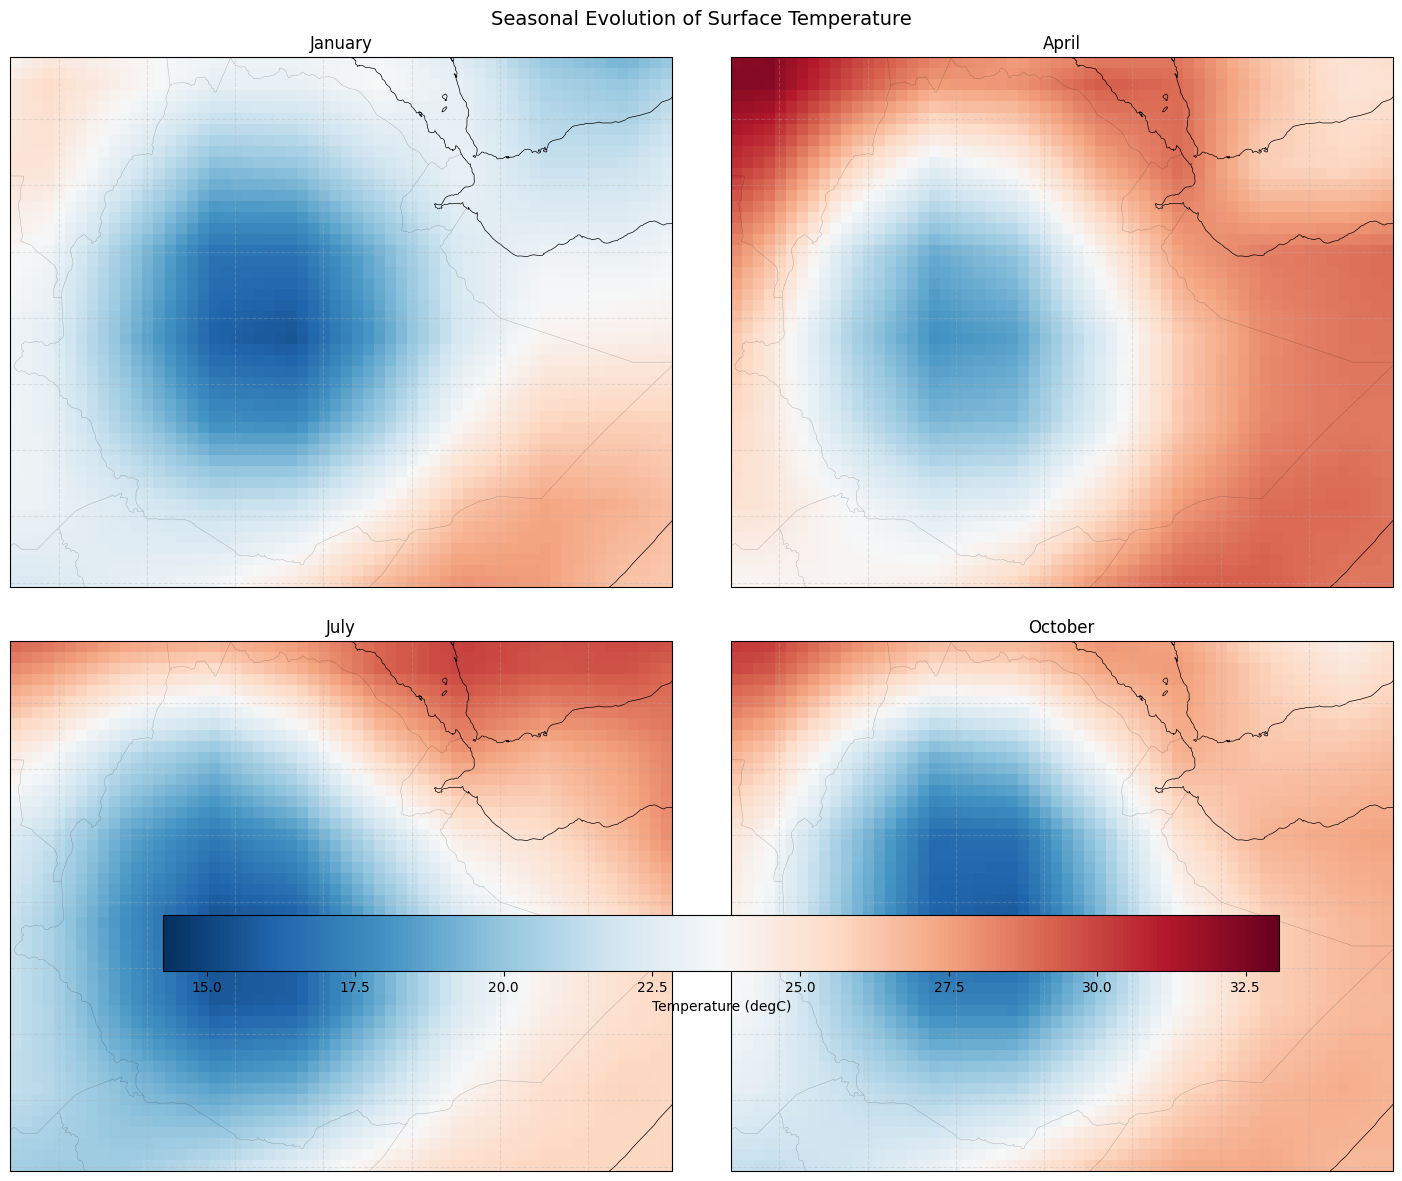

In [5]:
# Multiple subplot layouts
fig, axes = plt.subplots(2, 2, figsize=(16, 12),
                         subplot_kw={'projection': ccrs.PlateCarree()})

time_indices = [0, 3, 6, 9]  # Jan, Apr, Jul, Oct
month_names = ['January', 'April', 'July', 'October']

vmin = float(ds.temperature.min())
vmax = float(ds.temperature.max())

for ax, t_idx, mon_name in zip(axes.flat, time_indices, month_names):
    data_cyclic, lon_cyclic = ds.temperature[t_idx].values, ds.lon.values

    im = ax.pcolormesh(lon_cyclic, ds.lat, data_cyclic,
                       cmap='RdBu_r', transform=ccrs.PlateCarree(),
                       shading='auto', vmin=vmin, vmax=vmax)
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.3)
    ax.gridlines(draw_labels=False, linestyle='--', alpha=0.3)
    ax.set_title(f'{mon_name}')

fig.colorbar(im, ax=axes, orientation='horizontal', pad=0.05,
             label='Temperature (degC)', shrink=0.9)
plt.suptitle('Seasonal Evolution of Surface Temperature', fontsize=14)
plt.tight_layout()
plt.show()

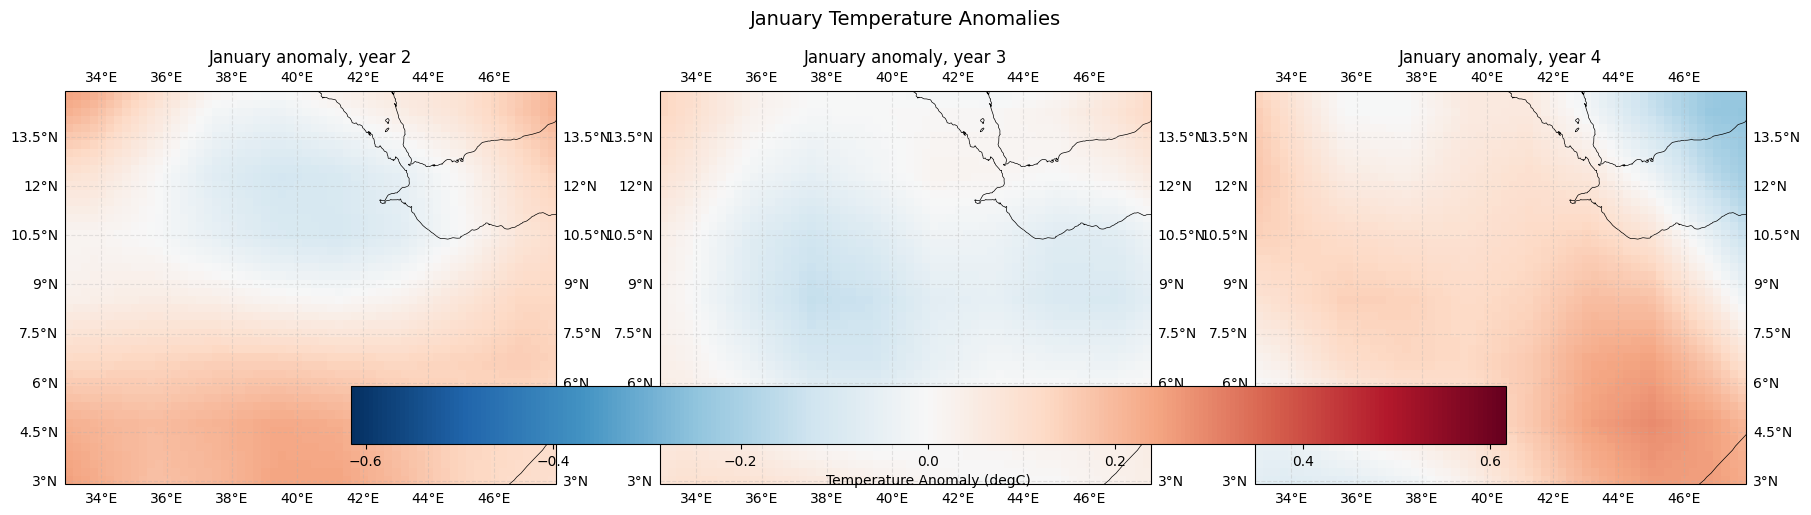

In [6]:
# Anomaly maps
# Compute monthly climatology and subtract from each month

clim = ds.temperature.groupby('time.month').mean('time')
anomalies = ds.temperature.groupby('time.month') - clim

# Plot anomalies for a specific month
fig, axes = plt.subplots(1, 3, figsize=(18, 5),
                         subplot_kw={'projection': ccrs.PlateCarree()})

anomaly_years = [1, 2, 3]  # January of year 2, 3, 4
titles = ['January anomaly, year 2', 'January anomaly, year 3', 'January anomaly, year 4']

vmax = max(abs(anomalies.min().values), abs(anomalies.max().values))

for ax, yr_idx, title in zip(axes, anomaly_years, titles):
    t_idx = yr_idx * 12  # January of each year
    if t_idx < len(ds.time):
        anom_data = anomalies[t_idx]
        data_cyclic, lon_cyclic = anom_data.values, ds.lon.values

        im = ax.pcolormesh(lon_cyclic, ds.lat, data_cyclic,
                           cmap='RdBu_r', transform=ccrs.PlateCarree(),
                           shading='auto', vmin=-vmax, vmax=vmax)
        ax.coastlines(linewidth=0.5)
        ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
        ax.set_title(title)

fig.colorbar(im, ax=axes, orientation='horizontal', pad=0.05,
             label='Temperature Anomaly (degC)', shrink=0.9)
plt.suptitle('January Temperature Anomalies', fontsize=14)
plt.tight_layout()
plt.show()

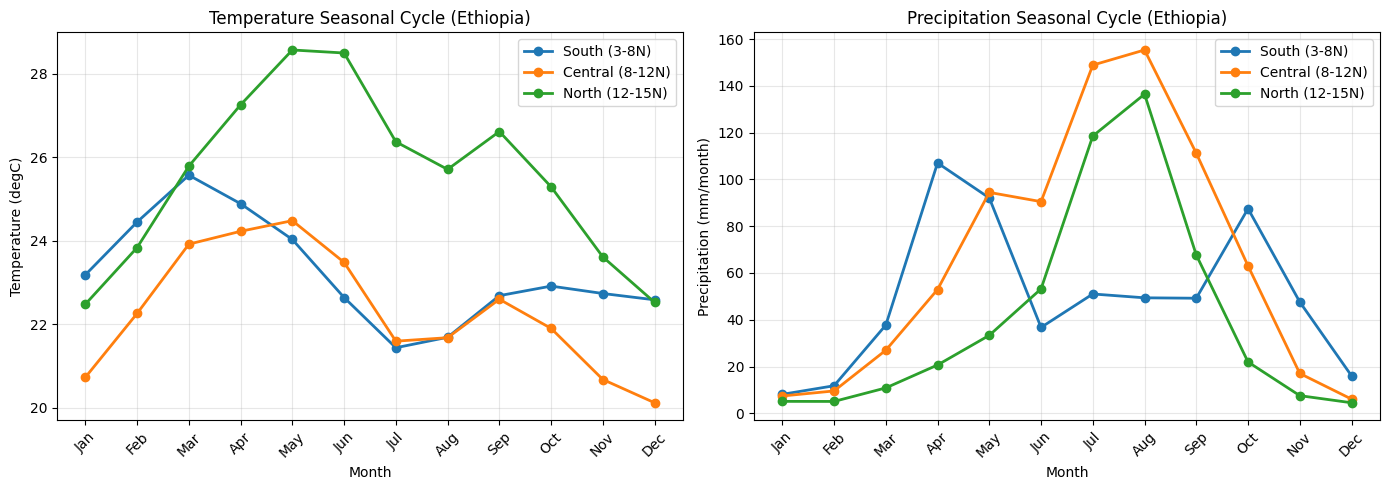

In [7]:
# Seasonal cycle at Ethiopian latitude bands (real CHIRPS/reanalysis domain)
months = np.arange(1, 13)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

lat_bands = [
    ('South (3-8N)', 3, 8),
    ('Central (8-12N)', 8, 12),
    ('North (12-15N)', 12, 15),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for var_name, ax, color, unit in [
    ('temperature', axes[0], 'red', 'degC'),
    ('precipitation', axes[1], 'blue', 'mm/month'),
]:
    clim_cycle = ds[var_name].groupby('time.month').mean('time')
    for band_name, lat_min, lat_max in lat_bands:
        band = clim_cycle.sel(lat=slice(lat_min, lat_max)).mean(dim=['lat', 'lon'])
        ax.plot(months, band.values, marker='o', linewidth=2, label=band_name)
    ax.set_xlabel('Month')
    ax.set_xticks(months)
    ax.set_xticklabels(month_labels, rotation=45)
    ax.set_ylabel(f'{var_name.capitalize()} ({unit})')
    ax.set_title(f'{var_name.capitalize()} Seasonal Cycle (Ethiopia)')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

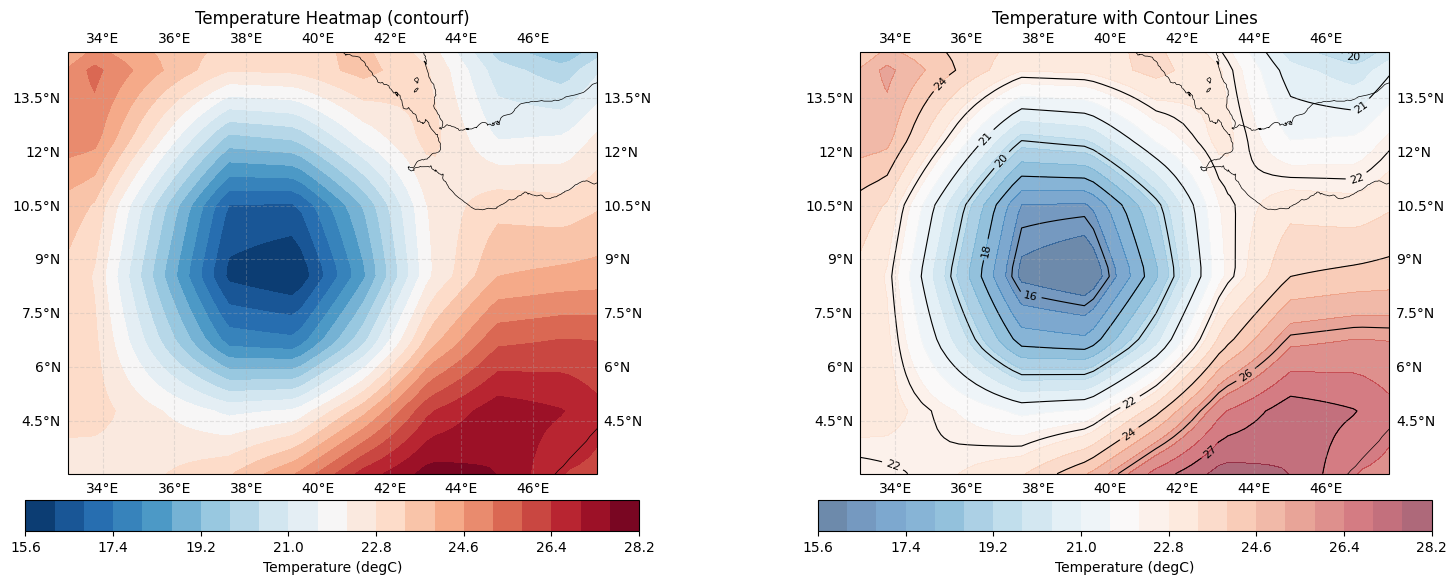

In [8]:
# Heatmaps and contour plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         subplot_kw={'projection': ccrs.PlateCarree()})

t_idx = 0  # January

# Heatmap (filled contours)
data_cyclic, lon_cyclic = ds.temperature[t_idx].values, ds.lon.values

im = axes[0].contourf(lon_cyclic, ds.lat, data_cyclic,
                       levels=20, cmap='RdBu_r', transform=ccrs.PlateCarree())
axes[0].coastlines(linewidth=0.5)
axes[0].gridlines(draw_labels=True, linestyle='--', alpha=0.3)
axes[0].set_title('Temperature Heatmap (contourf)')
plt.colorbar(im, ax=axes[0], orientation='horizontal', pad=0.05,
             label='Temperature (degC)', shrink=0.8)

# Contour lines
cs = axes[1].contour(lon_cyclic, ds.lat, data_cyclic,
                     levels=10, colors='black', linewidths=0.8,
                     transform=ccrs.PlateCarree())
axes[1].clabel(cs, inline=True, fontsize=8, fmt='%.0f')
im2 = axes[1].contourf(lon_cyclic, ds.lat, data_cyclic,
                       levels=20, cmap='RdBu_r', transform=ccrs.PlateCarree(), alpha=0.6)
axes[1].coastlines(linewidth=0.5)
axes[1].gridlines(draw_labels=True, linestyle='--', alpha=0.3)
axes[1].set_title('Temperature with Contour Lines')
plt.colorbar(im2, ax=axes[1], orientation='horizontal', pad=0.05,
             label='Temperature (degC)', shrink=0.8)

plt.tight_layout()
plt.show()

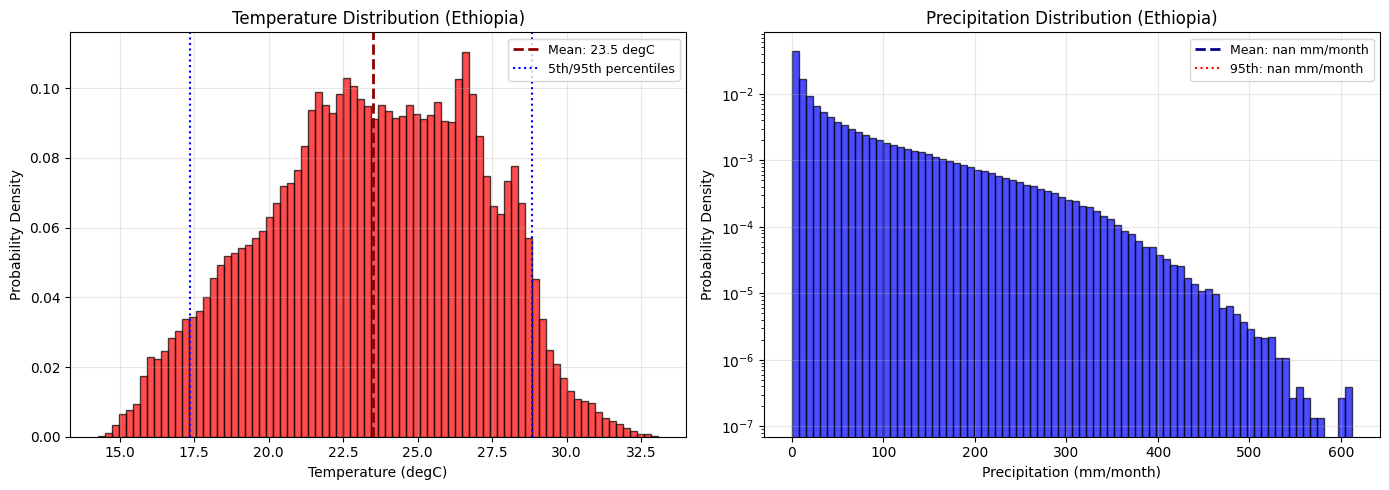

Sample statistics:
  Temperature: mean=23.5, std=3.5 degC
  Precipitation: mean=nan, std=nan mm/month


In [9]:
# Histogram of climate variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Collect all grid point data from all timesteps
all_temps = ds.temperature.values.flatten()
all_precip = ds.precipitation.values.flatten()

# Temperature histogram
axes[0].hist(all_temps, bins=80, color='red', alpha=0.7, edgecolor='black', density=True)
axes[0].axvline(np.mean(all_temps), color='darkred', linewidth=2,
                linestyle='--', label=f'Mean: {np.mean(all_temps):.1f} degC')
axes[0].axvline(np.percentile(all_temps, 5), color='blue', linewidth=1.5,
                linestyle=':', label='5th/95th percentiles')
axes[0].axvline(np.percentile(all_temps, 95), color='blue', linewidth=1.5, linestyle=':')
axes[0].set_xlabel('Temperature (degC)')
axes[0].set_ylabel('Probability Density')
axes[0].set_title('Temperature Distribution (Ethiopia)')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Precipitation histogram (log scale)
axes[1].hist(all_precip, bins=80, color='blue', alpha=0.7, edgecolor='black', density=True)
axes[1].axvline(np.mean(all_precip), color='darkblue', linewidth=2,
                linestyle='--', label=f'Mean: {np.mean(all_precip):.2f} mm/month')
axes[1].axvline(np.percentile(all_precip, 95), color='red', linewidth=1.5,
                linestyle=':', label=f'95th: {np.percentile(all_precip, 95):.2f} mm/month')
axes[1].set_xlabel('Precipitation (mm/month)')
axes[1].set_ylabel('Probability Density')
axes[1].set_title('Precipitation Distribution (Ethiopia)')
axes[1].set_yscale('log')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Sample statistics:')
print(f'  Temperature: mean={np.mean(all_temps):.1f}, std={np.std(all_temps):.1f} degC')
print(f'  Precipitation: mean={np.mean(all_precip):.2f}, std={np.std(all_precip):.2f} mm/month')

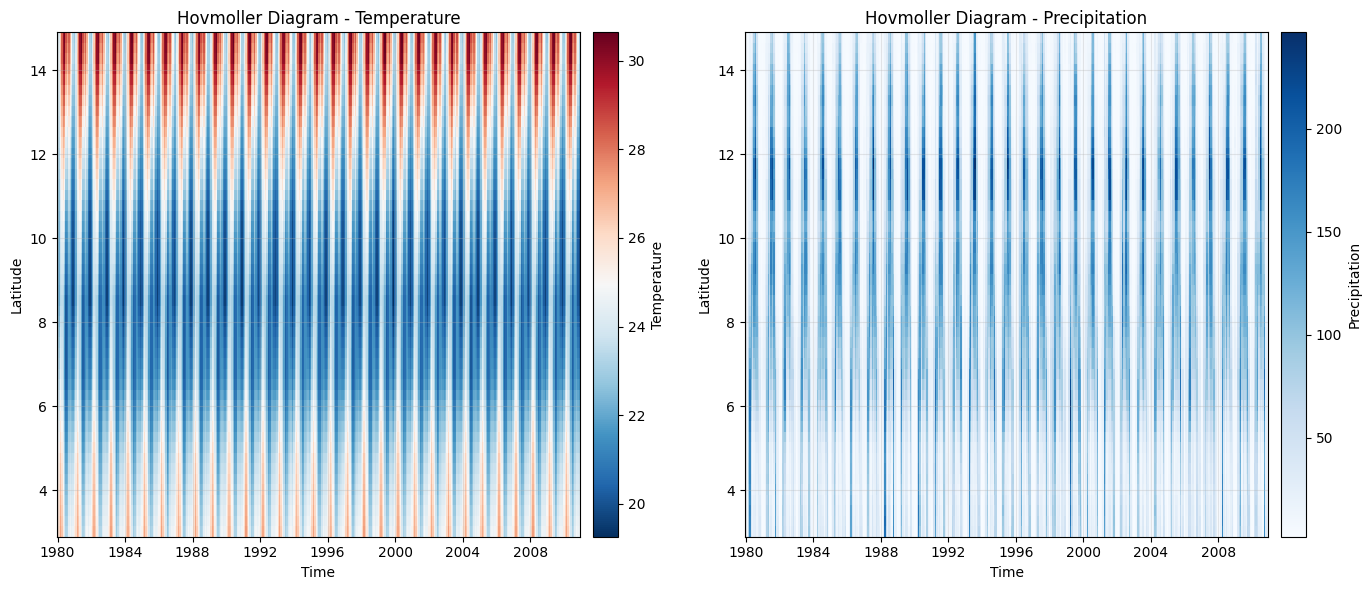

In [10]:
# Advanced: Hovmoller diagram (time-latitude cross-section)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for var_name, ax, cmap in [('temperature', axes[0], 'RdBu_r'),
                            ('precipitation', axes[1], 'Blues')]:
    # Zonal mean
    zonal_mean = ds[var_name].mean(dim='lon')

    im = ax.pcolormesh(zonal_mean.time, zonal_mean.lat,
                       zonal_mean.values.T, cmap=cmap, shading='auto')
    ax.set_xlabel('Time')
    ax.set_ylabel('Latitude')
    ax.set_title(f'Hovmoller Diagram - {var_name.capitalize()}')
    plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02,
                 label=f'{var_name.capitalize()}')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Exercises

1. Create a 2x3 panel of global maps showing precipitation for each month of a year
2. Use the `coolwarm` and `viridis` colormaps instead of `RdBu_r` and `Blues` and compare
3. Create a scatter plot of temperature vs. precipitation for all grid points
4. Add topographic features to a map using `cfeature.SHAPE_RESOLUTION`
5. Create an animation of the seasonal cycle (hint: use matplotlib.animation or generate frames)

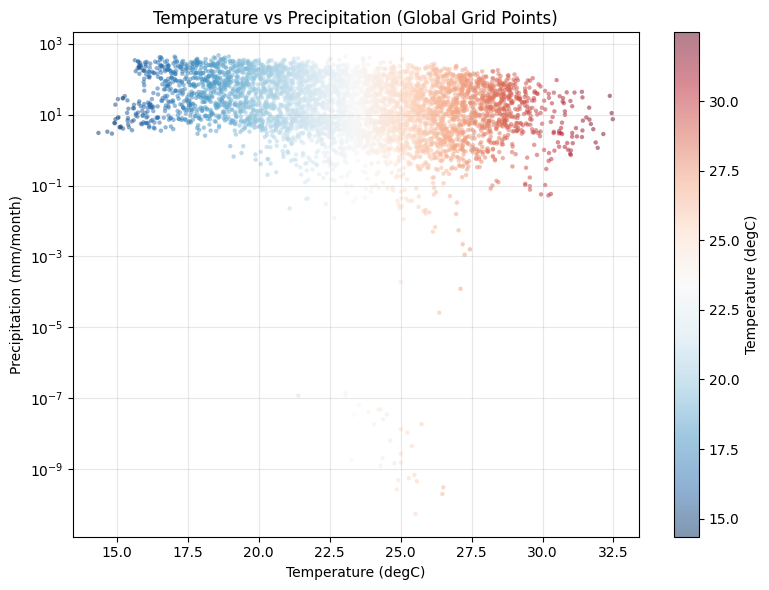

In [11]:
# Exercise 3: Temperature vs Precipitation scatter plot
fig, ax = plt.subplots(figsize=(8, 6))

# Sample a deterministic subset of real data points for clarity
n_sample = min(5000, len(all_temps))
idx = np.linspace(0, len(all_temps) - 1, n_sample).astype(int)

sc = ax.scatter(all_temps[idx], all_precip[idx], c=all_temps[idx],
                cmap='RdBu_r', alpha=0.5, s=10, edgecolors='none')
ax.set_xlabel('Temperature (degC)')
ax.set_ylabel('Precipitation (mm/month)')
ax.set_title('Temperature vs Precipitation (Global Grid Points)')
ax.set_yscale('log')
plt.colorbar(sc, ax=ax, label='Temperature (degC)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

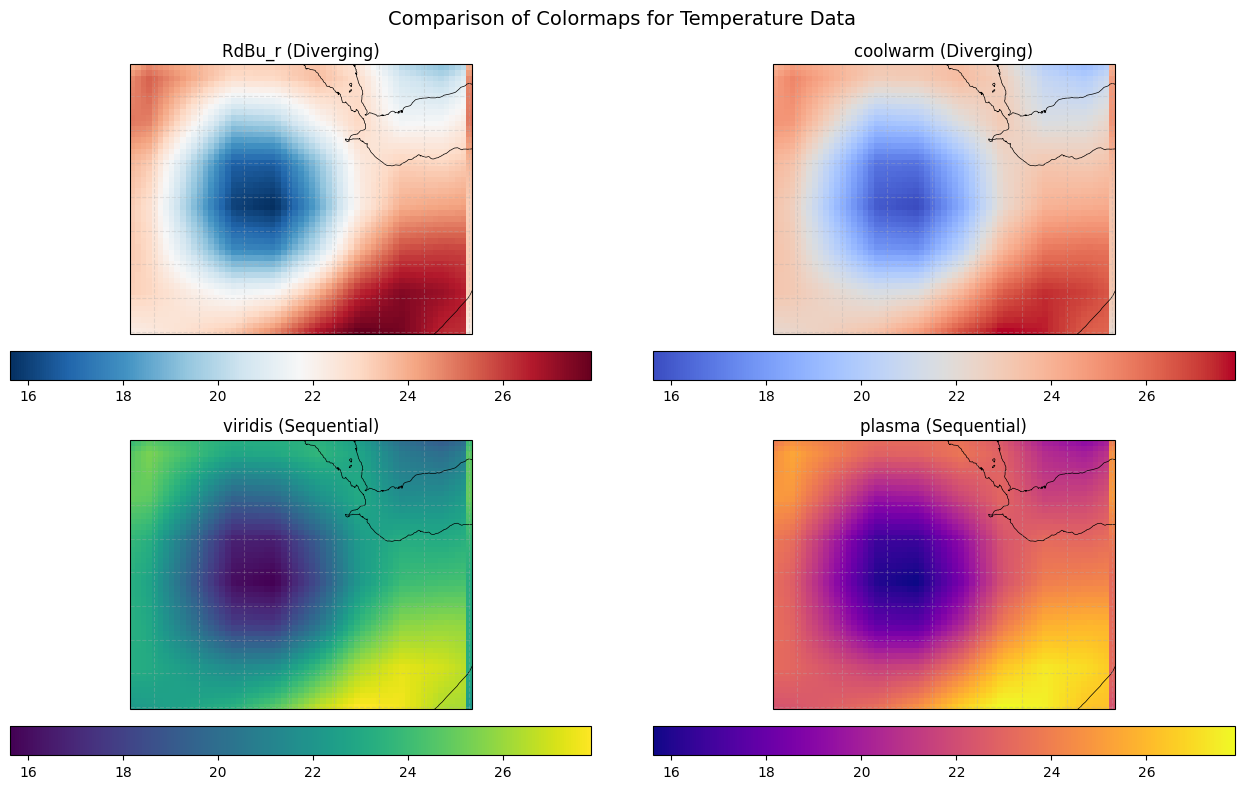

In [12]:
# Exercise 2: Different colormaps comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 8),
                         subplot_kw={'projection': ccrs.PlateCarree()})

colormaps = [('RdBu_r', 'Diverging'), ('coolwarm', 'Diverging'),
             ('viridis', 'Sequential'), ('plasma', 'Sequential')]

for ax, (cmap_name, cmap_type) in zip(axes.flat, colormaps):
    data_cyclic, lon_cyclic = add_cyclic_point(
        ds.temperature[0], coord=ds.lon.values)

    im = ax.pcolormesh(lon_cyclic, ds.lat, data_cyclic,
                       cmap=cmap_name, transform=ccrs.PlateCarree(), shading='auto')
    ax.coastlines(linewidth=0.5)
    ax.set_title(f'{cmap_name} ({cmap_type})')
    ax.gridlines(draw_labels=False, linestyle='--', alpha=0.3)
    plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)

plt.suptitle('Comparison of Colormaps for Temperature Data', fontsize=14)
plt.tight_layout()
plt.show()